#  Credit Scoring Model — Base Version (Google Colab)

**Objective:** Predict an individual's creditworthiness (default vs. no default) from past financial data.

**Dataset:** [Default of Credit Card Clients Dataset (UCI, via Kaggle)](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset)
- 30,000 credit card clients from a Taiwanese bank (2005)
- Features: credit limit, sex, education, marriage, age, 6 months of payment history, bill amounts, payment amounts
- Target: `default.payment.next.month` (1 = default, 0 = no default)

This notebook covers the **base pipeline**:
`Load data → Understand → EDA → Preprocess → Feature Engineering → Baseline Models → Evaluation → Prediction function`

> This is intentionally the "base version" — good for an academic submission. Once this runs end-to-end, you can layer on XGBoost, SMOTE, SHAP, hyperparameter tuning, FastAPI, and Streamlit (see the upgrade roadmap you already have).


## 0. Get the dataset into Colab

Pick **one** of the two options below.

**Option A — Kaggle API (recommended):**
1. Go to [kaggle.com](https://www.kaggle.com) → your profile → *Settings* → *API* → **Create New Token**. This downloads `kaggle.json`.
2. Run the cell below and upload `kaggle.json` when prompted.

**Option B — Manual upload:**
Download the CSV yourself from the [Kaggle dataset page](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset), then use Colab's file upload widget (second code cell) to upload `UCI_Credit_Card.csv` directly, and skip Option A.


In [5]:
#OPTION B: Manual upload (skip this if you used Option A above)
from google.colab import files
uploaded = files.upload()  # choose UCI_Credit_Card.csv from your computer


Saving UCI_Credit_Card.csv to UCI_Credit_Card (1).csv


## A–B. Load Data & Data Understanding

In [6]:
import pandas as pd
import numpy as np

# The Kaggle download unzips to this filename; adjust if you used Option B
df = pd.read_csv("UCI_Credit_Card.csv")

print("Shape:", df.shape)
df.head()


Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

In [8]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [9]:
# Rename target column for convenience
df = df.rename(columns={"default.payment.next.month": "default"})

# ID column is not predictive - drop it
if "ID" in df.columns:
    df = df.drop(columns=["ID"])

print(df.columns.tolist())


['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default']


In [10]:
# Identify categorical vs numerical variables
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE"] + [f"PAY_{i}" for i in [0,2,3,4,5,6]]
categorical_cols = [c for c in categorical_cols if c in df.columns]

numerical_cols = [c for c in df.columns if c not in categorical_cols + ["default"]]

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)


Categorical columns: ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
Numerical columns: ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [11]:
# Missing values
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Duplicates
print("\nDuplicate rows:", df.duplicated().sum())

# Target distribution
print("\nTarget distribution:")
print(df["default"].value_counts())
print(df["default"].value_counts(normalize=True).round(3))


Missing values per column:
Series([], dtype: int64)

Duplicate rows: 35

Target distribution:
default
0    23364
1     6636
Name: count, dtype: int64
default
0    0.779
1    0.221
Name: proportion, dtype: float64


In [12]:
# EDUCATION and MARRIAGE have some undocumented/out-of-range codes (0, 5, 6) - clean them
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})  # fold into "others"
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})  # fold into "others"

df = df.drop_duplicates()
print("Shape after cleaning:", df.shape)


Shape after cleaning: (29965, 24)


## C. Exploratory Data Analysis

/tmp/ipykernel_3227/2572191025.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["No Default", "Default"])


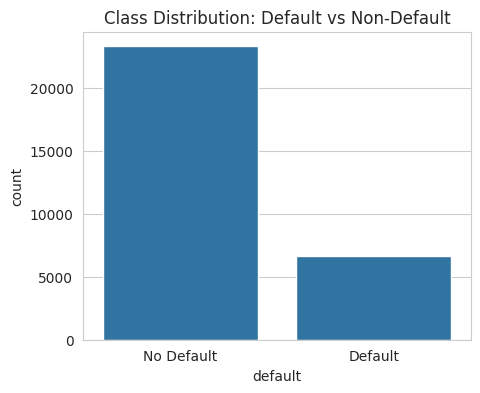

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

fig, ax = plt.subplots(figsize=(5,4))
sns.countplot(data=df, x="default", ax=ax)
ax.set_xticklabels(["No Default", "Default"])
ax.set_title("Class Distribution: Default vs Non-Default")
plt.show()


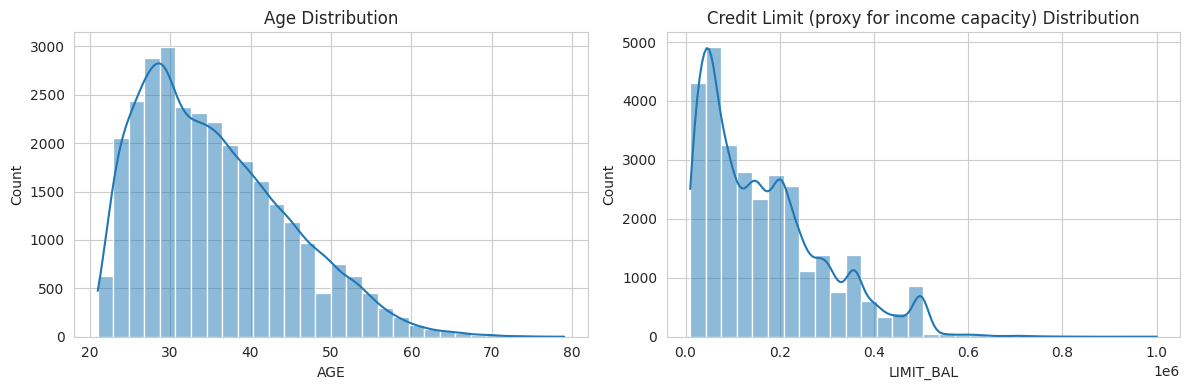

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df["AGE"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

sns.histplot(df["LIMIT_BAL"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Credit Limit (proxy for income capacity) Distribution")
plt.tight_layout()
plt.show()


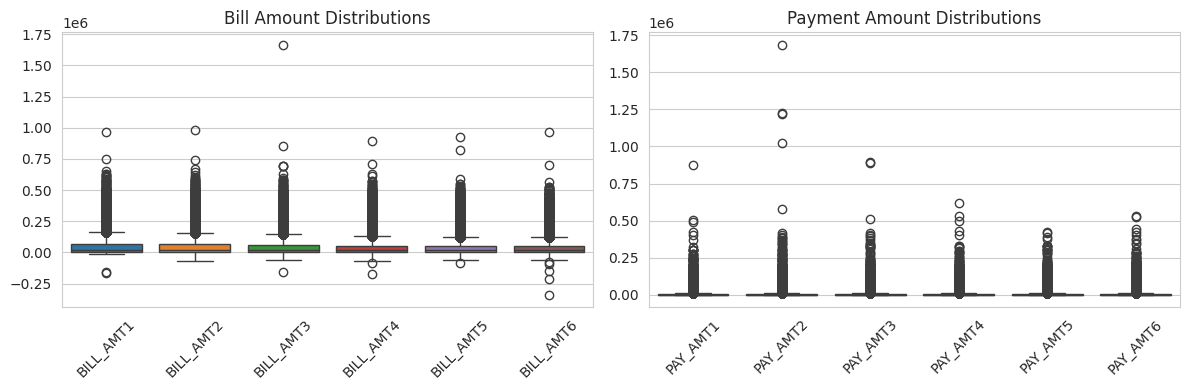

In [15]:
bill_cols = [c for c in df.columns if c.startswith("BILL_AMT")]
pay_cols = [c for c in df.columns if c.startswith("PAY_AMT")]

fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(data=df[bill_cols], ax=axes[0])
axes[0].set_title("Bill Amount Distributions")
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df[pay_cols], ax=axes[1])
axes[1].set_title("Payment Amount Distributions")
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


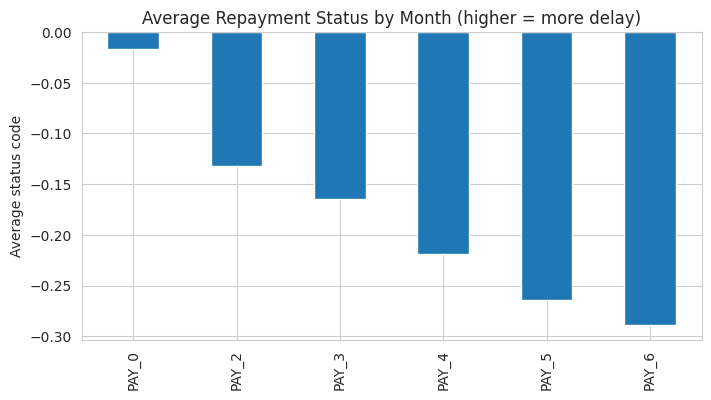

In [16]:
pay_status_cols = [c for c in df.columns if c.startswith("PAY_") and not c.startswith("PAY_AMT")]

fig, ax = plt.subplots(figsize=(8,4))
df[pay_status_cols].mean().plot(kind="bar", ax=ax)
ax.set_title("Average Repayment Status by Month (higher = more delay)")
ax.set_ylabel("Average status code")
plt.show()


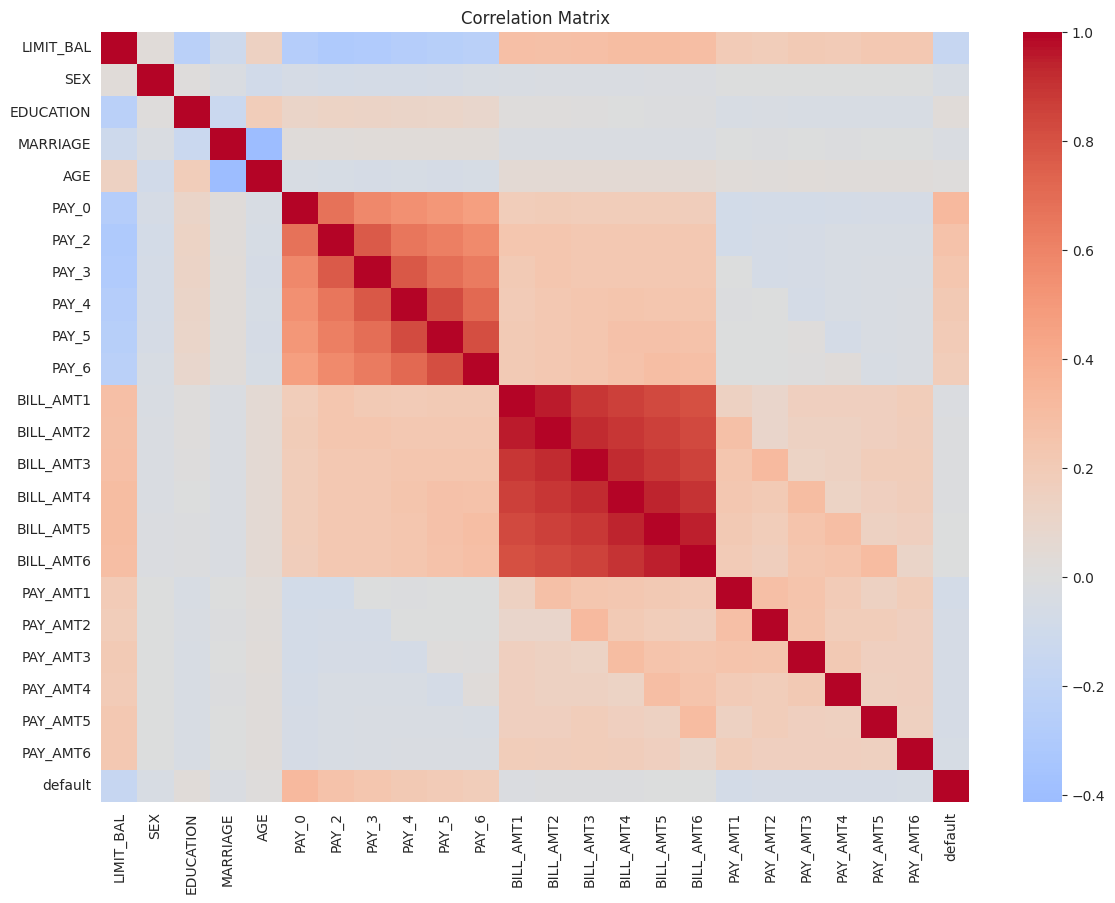

In [17]:
plt.figure(figsize=(14,10))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Matrix")
plt.show()


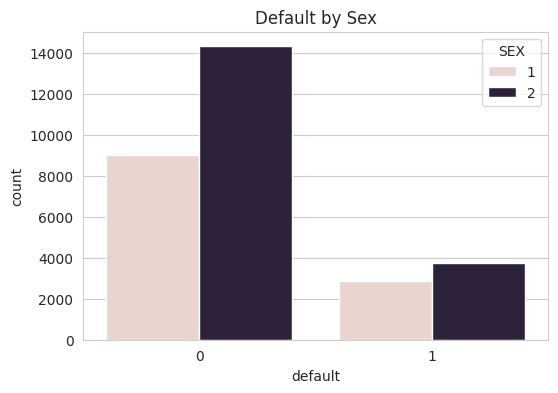

In [18]:
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(data=df, x="default", hue="SEX", ax=ax)
ax.set_title("Default by Sex")
plt.show()


## D. Data Preprocessing

**Important:** to avoid data leakage, we split into train/test *first*, then fit any scaler/encoder only on the training data and apply it to the test data.


In [19]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["default"])
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train target balance:\n", y_train.value_counts(normalize=True).round(3))


Train shape: (23972, 23)  Test shape: (5993, 23)
Train target balance:
 default
0    0.779
1    0.221
Name: proportion, dtype: float64


## E. Feature Engineering

Financial-history features that generally improve credit-risk models:
- **Debt-to-Income Ratio proxy**: average bill amount / credit limit
- **Credit Utilization**: how much of the credit line is being used
- **Payment-to-Bill Ratio**: how much of the bill was actually paid
- **Payment Delay Indicator**: count of months with delayed payment
- **Age Group / Income (credit-limit) Group**: bucketed versions of continuous variables

We engineer these with a small function so the *exact same* logic is applied to train and test (and later, to any new customer at prediction time) — this keeps things leak-free and reusable.


In [20]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()

    bill_cols = [c for c in data.columns if c.startswith("BILL_AMT")]
    pay_amt_cols = [c for c in data.columns if c.startswith("PAY_AMT")]
    pay_status_cols = [c for c in data.columns if c.startswith("PAY_") and not c.startswith("PAY_AMT")]

    data["avg_bill_amt"] = data[bill_cols].mean(axis=1)
    data["avg_pay_amt"] = data[pay_amt_cols].mean(axis=1)

    # Credit utilization: average bill relative to credit limit (capped at 0 to avoid negative from overpayment)
    data["credit_utilization"] = (data["avg_bill_amt"] / data["LIMIT_BAL"]).clip(lower=0)

    # Debt-to-income proxy: since we don't have separate income, use LIMIT_BAL as an income proxy
    data["debt_to_limit_ratio"] = (data["avg_bill_amt"] / data["LIMIT_BAL"]).replace([np.inf, -np.inf], 0)

    # Payment-to-bill ratio: how much of what was billed got paid, on average
    data["payment_to_bill_ratio"] = (data["avg_pay_amt"] / data["avg_bill_amt"].replace(0, np.nan))
    data["payment_to_bill_ratio"] = data["payment_to_bill_ratio"].replace([np.inf, -np.inf], np.nan).fillna(0)

    # Payment delay indicator: how many of the last 6 months had a delay (status > 0)
    data["num_months_delayed"] = (data[pay_status_cols] > 0).sum(axis=1)
    data["max_delay"] = data[pay_status_cols].max(axis=1)

    # Age groups
    data["age_group"] = pd.cut(
        data["AGE"], bins=[0, 25, 35, 45, 55, 100],
        labels=["<=25", "26-35", "36-45", "46-55", "56+"]
    )

    # Credit-limit ("income") groups, using quartiles learned elsewhere would leak;
    # fixed, business-meaningful bins avoid that problem
    data["limit_group"] = pd.cut(
        data["LIMIT_BAL"], bins=[0, 50000, 150000, 300000, np.inf],
        labels=["low", "medium", "high", "very_high"]
    )

    return data

X_train_fe = engineer_features(X_train)
X_test_fe = engineer_features(X_test)

new_feature_cols = ["avg_bill_amt", "avg_pay_amt", "credit_utilization", "debt_to_limit_ratio",
                     "payment_to_bill_ratio", "num_months_delayed", "max_delay",
                     "age_group", "limit_group"]
X_train_fe[new_feature_cols].head()


,avg_bill_amt,avg_pay_amt,credit_utilization,debt_to_limit_ratio,payment_to_bill_ratio,num_months_delayed,max_delay,age_group,limit_group
27420,0.000000,0.000000,0.000000,0.000000,0.000000,0,-2,26-35,high
15350,41233.166667,1400.000000,0.824663,0.824663,0.033953,6,2,36-45,low
26641,592.000000,543.000000,0.007400,0.007400,0.917230,0,0,<=25,medium
21618,671.333333,606.333333,0.013427,0.013427,0.903178,0,-1,26-35,low
11570,84685.166667,36465.000000,0.423426,0.423426,0.430595,0,-2,26-35,high


In [21]:
# One-hot encode the categorical / bucketed columns.
# fit the encoder on TRAIN ONLY, then apply the same columns to test (no leakage).
categorical_for_ohe = ["SEX", "EDUCATION", "MARRIAGE", "age_group", "limit_group"]
categorical_for_ohe = [c for c in categorical_for_ohe if c in X_train_fe.columns]

X_train_enc = pd.get_dummies(X_train_fe, columns=categorical_for_ohe, drop_first=True)
X_test_enc = pd.get_dummies(X_test_fe, columns=categorical_for_ohe, drop_first=True)

# Align columns (test might be missing a rare category level) - fill missing with 0
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

print(X_train_enc.shape, X_test_enc.shape)


(23972, 40) (5993, 40)


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train_enc)  # fit on TRAIN only

X_train_scaled = pd.DataFrame(scaler.transform(X_train_enc), columns=X_train_enc.columns, index=X_train_enc.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_enc), columns=X_test_enc.columns, index=X_test_enc.index)

X_train_scaled.head()


,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,...,EDUCATION_4,MARRIAGE_2,MARRIAGE_3,age_group_26-35,age_group_36-45,age_group_46-55,age_group_56+,limit_group_medium,limit_group_high,limit_group_very_high
27420,1.022024,-0.050264,-1.771947,-1.566494,-1.544266,-1.530037,-1.538794,-1.492534,-0.700030,-0.694464,...,-0.126574,-1.067965,-0.114834,1.147132,-0.630960,-0.38016,-0.170217,-0.638915,1.524134,-0.423528
15350,-0.903020,0.167213,1.793738,1.781057,1.818359,1.906811,2.010259,2.005012,-0.049079,-0.005582,...,-0.126574,-1.067965,8.708234,-0.871739,1.584887,-0.38016,-0.170217,-0.638915,-0.656110,-0.423528
26641,-0.672015,-1.355126,-0.880526,-0.729606,-0.703609,-0.670825,0.235732,0.256239,-0.693968,-0.688208,...,-0.126574,0.936361,-0.114834,-0.871739,-0.630960,-0.38016,-0.170217,1.565153,-0.656110,-0.423528
21618,-0.903020,-1.028910,-0.880526,-0.729606,-0.703609,-0.670825,-0.651531,-0.618147,-0.694705,-0.665187,...,-0.126574,0.936361,-0.114834,1.147132,-0.630960,-0.38016,-0.170217,-0.638915,-0.656110,-0.423528
11570,0.252006,-0.593956,-1.771947,-1.566494,-1.544266,-1.530037,-1.538794,-1.492534,-0.037938,0.009043,...,-0.126574,0.936361,-0.114834,1.147132,-0.630960,-0.38016,-0.170217,-0.638915,1.524134,-0.423528


## F. Machine Learning — Baseline Models

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, n_jobs=-1),
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"Trained: {name}")


Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest


## G. Model Evaluation (beyond accuracy)

In [24]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.810,0.657,0.294,0.406,0.753
Decision Tree,0.814,0.635,0.379,0.474,0.758
Random Forest,0.820,0.668,0.371,0.477,0.776


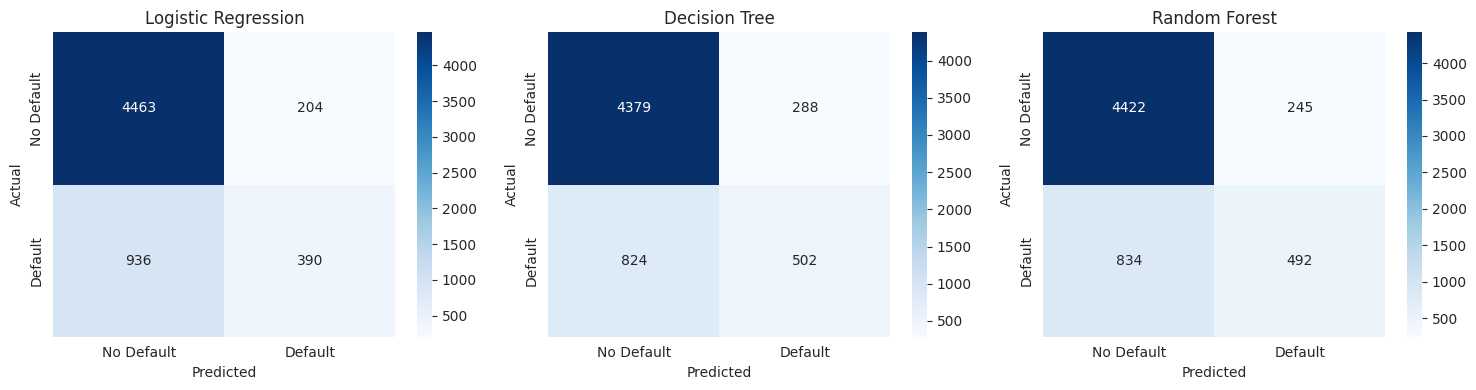

In [25]:
fig, axes = plt.subplots(1, len(models), figsize=(5*len(models), 4))
for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No Default", "Default"], yticklabels=["No Default", "Default"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


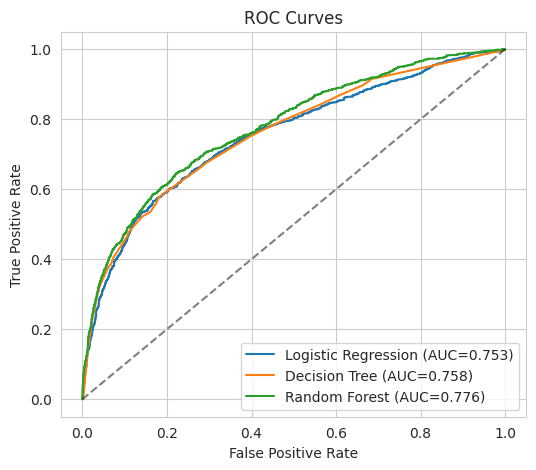

In [26]:
plt.figure(figsize=(6,5))
for name, model in models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0,1], [0,1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()


In [27]:
best_model_name = results_df["ROC-AUC"].idxmax()
best_model = models[best_model_name]
print(f"Best model by ROC-AUC: {best_model_name}")
print()
print(classification_report(y_test, best_model.predict(X_test_scaled), target_names=["No Default", "Default"]))


Best model by ROC-AUC: Random Forest

              precision    recall  f1-score   support

  No Default       0.84      0.95      0.89      4667
     Default       0.67      0.37      0.48      1326

    accuracy                           0.82      5993
   macro avg       0.75      0.66      0.68      5993
weighted avg       0.80      0.82      0.80      5993



## H. Prediction — score a new customer

This function takes a raw customer record (same columns as the original dataset, minus the target),
runs it through the *exact same* feature engineering, encoding, and scaling used for training, and
returns a default-risk prediction. This is what you'd later wrap in a FastAPI endpoint.


In [28]:
def predict_default_risk(customer_dict: dict, model=best_model) -> dict:
    """
    customer_dict: dict of raw feature values, e.g.
        {"LIMIT_BAL": 50000, "SEX": 1, "EDUCATION": 2, "MARRIAGE": 1, "AGE": 30,
         "PAY_0": 0, "PAY_2": 0, "PAY_3": 0, "PAY_4": 0, "PAY_5": 0, "PAY_6": 0,
         "BILL_AMT1": 3000, ..., "PAY_AMT1": 2000, ...}
    """
    row = pd.DataFrame([customer_dict])

    # Fill any columns missing from the input with the training median (robust default)
    for col in X_train.columns:
        if col not in row.columns:
            row[col] = X_train[col].median()
    row = row[X_train.columns]

    row_fe = engineer_features(row)
    row_enc = pd.get_dummies(row_fe, columns=categorical_for_ohe)
    row_enc = row_enc.reindex(columns=X_train_enc.columns, fill_value=0)
    row_scaled = scaler.transform(row_enc)

    proba = model.predict_proba(row_scaled)[0, 1]
    pred = model.predict(row_scaled)[0]

    risk_band = "High" if proba >= 0.5 else ("Medium" if proba >= 0.25 else "Low")

    return {
        "prediction": "Default" if pred == 1 else "No Default",
        "default_probability": round(float(proba), 3),
        "risk_band": risk_band,
    }

# Example usage
sample_customer = {
    "LIMIT_BAL": 20000, "SEX": 1, "EDUCATION": 2, "MARRIAGE": 1, "AGE": 24,
    "PAY_0": 2, "PAY_2": 2, "PAY_3": 2, "PAY_4": 0, "PAY_5": 0, "PAY_6": 0,
    "BILL_AMT1": 3913, "BILL_AMT2": 3102, "BILL_AMT3": 689, "BILL_AMT4": 0,
    "BILL_AMT5": 0, "BILL_AMT6": 0,
    "PAY_AMT1": 0, "PAY_AMT2": 689, "PAY_AMT3": 0, "PAY_AMT4": 0,
    "PAY_AMT5": 0, "PAY_AMT6": 0,
}

predict_default_risk(sample_customer)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


{'prediction': 'Default', 'default_probability': 0.685, 'risk_band': 'High'}

## Next steps (upgrade path)

This notebook is the solid "base version." To make it a stronger, resume-worthy project, in this order:

1. **XGBoost** — add as a fourth model in the `models` dict and compare.
2. **Class imbalance handling** — try `class_weight="balanced"` and SMOTE (`imbalanced-learn`), compare against baseline.
3. **Threshold optimization** — sweep thresholds 0.1–0.9 on `predict_proba` and plot precision/recall/F1 vs. threshold.
4. **SHAP explainability** — `shap.TreeExplainer` on the Random Forest / XGBoost model for global + individual explanations.
5. **Hyperparameter tuning** — `RandomizedSearchCV` / `GridSearchCV` with 5-fold cross-validation.
6. **Wrap in `sklearn.Pipeline`** so preprocessing + model become one reusable object (also makes leakage far harder to introduce by accident).
7. **Deploy** — FastAPI `/predict` endpoint calling `predict_default_risk`, then a Streamlit front end.


